In [2]:
import copy
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
import torch.nn as nn
import torch.nn.functional as F
import rl_mind.envs
from dataclasses import dataclass, replace
from scipy import stats
from torch import Tensor
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm
from rl_mind.core import Action, Actor
from rl_mind.nn import build_mlp, soft_update
from rl_mind.env import VecEnv
from rl_mind.data import ReplayBuffer, Transitions
from rl_mind.collectors import TransitionCollector
from rl_mind.evaluation import Evaluator
from rl_mind.notebook import run_directory, setup_tensorboard, silence_known_warnings


In [3]:
# pygame and tensorboard still use the deprecated `pkg_resources` API
silence_known_warnings()

In [4]:
def add_layernorm(model: nn.Module):
    layers = list(model.children())
    linear_indices = [i for i, layer in enumerate(layers)if isinstance(layer, nn.Linear)]
    last_linear_index = linear_indices[-1]
    new_layers = []
    for i, layer in enumerate(layers):
        new_layers.append(layer)
        if isinstance(layer, nn.Linear) and i != last_linear_index:
            new_layers.append(nn.LayerNorm(layer.out_features))
    return nn.Sequential(*new_layers)

In [5]:
@dataclass(frozen=True)
class DDPGConfig:
    env_name: str = "LunarLander-v3"
    seed: int = 1

    use_layernorm: bool = False

    max_steps: int = 30_000
    n_envs: int = 1
    steps_per_update: int = 1
    learning_starts: int = 1_000

    buffer_size: int = 200_000
    batch_size: int = 64

    gamma: float = 0.98
    tau: float = 0.05
    action_noise: float = 0.1

    actor_hidden: tuple[int, ...] = (256, 256)
    critic_hidden: tuple[int, ...] = (256, 256)
    lr_actor: float = 1e-3
    lr_critic: float = 1e-3

    eval_interval: int = 2_000
    n_eval_envs: int = 10

In [6]:
class ContinuousQNetwork(nn.Module):
    """The Q-network $Q(s, a)$ for continuous actions"""

    def __init__(self, obs_dim: int, hidden: tuple[int, ...], action_dim: int, use_layernorm: bool = False):
        super().__init__()
        self.model = build_mlp([obs_dim + action_dim, *hidden, 1])
        if use_layernorm:
            self.model = add_layernorm(self.model)

    def forward(self, obs: Tensor, action: Tensor) -> Tensor:
        """Compute $Q(s, a)$ for a batch: `[B, obs_dim] x [B, action_dim] -> [B]`"""
        return self.model(torch.cat([obs, action], dim=1)).squeeze(-1)

In [7]:
class ContinuousDeterministicActor(Actor[Action]):
    def __init__(self, obs_dim: int, hidden: tuple[int, ...], action_dim: int, use_layernorm: bool = False):
        """Creates a new actor with continuous actions in `action_dim` dimensions.

        :param obs_dim: The dimension of the observation space
        :param hidden: A tuple of integers specifying the sizes of the hidden layers
        :param action_dim: The dimension of the action space
        """
        super().__init__()
        self.model = build_mlp([obs_dim, *hidden, action_dim], output_activation=nn.Tanh())
        if use_layernorm:
            self.model = add_layernorm(self.model)

    def forward(self, obs: Tensor) -> Action:
        return Action(value=self.model(obs))

In [8]:
class GaussianNoise(Actor[Action]):
    """Adds Gaussian noise to the actions of another actor (at training time)"""

    def __init__(self, actor: Actor[Action], sigma: float):
        super().__init__()
        self.actor = actor
        self.sigma = sigma

    def forward(self, obs: Tensor) -> Action:
        action = self.actor(obs).value
        noisy_action = action + self.sigma * torch.randn_like(action)
        noisy_action = noisy_action.clamp(-1.0, 1.0)
        return Action(value=noisy_action)

    def act(self, obs: Tensor) -> Tensor:
        return self.actor.act(obs)

In [9]:
def compute_critic_loss(
    gamma: float, batch: Transitions[Action], q_values: Tensor, next_q_values: Tensor
) -> Tensor:
    """Compute the DDPG critic loss from a batch of transitions

    :param gamma: The discount factor
    :param batch: The batch of transitions
    :param q_values: $Q(s_t, a_t)$ from the critic (shape `[B]`)
    :param next_q_values: $Q'(s_{t+1}, \\pi(s_{t+1}))$ from the target critic
        (shape `[B]`)
    :return: The critic loss (a scalar)
    """
    # Compute the target (do not bootstrap when `batch.terminated`), then the MSE loss
    target = batch.reward + gamma * (~batch.terminated) * next_q_values
    return F.mse_loss(q_values, target)


In [10]:
def compute_actor_loss(q_values: Tensor) -> Tensor:
    """Return the actor loss given $Q(s_t, \\pi(s_t))$ (shape `[B]`)"""
    # Compute the actor loss
    return -q_values.mean()


# TD3

In [11]:
@dataclass(frozen=True)
class TD3Config(DDPGConfig):
    #: Number of critic updates between two policy updates
    policy_delay: int = 2
    #: Std of the noise added to the target policy actions
    target_noise: float = 0.2
    #: Clipping of the target policy noise
    target_noise_clip: float = 0.5

In [12]:
def run_td3(cfg: TD3Config) -> Evaluator:
    torch.manual_seed(cfg.seed)
    env = VecEnv(
        cfg.env_name, cfg.n_envs,
        seed=cfg.seed, continuous=True
    )

    actor = ContinuousDeterministicActor(
        env.observation_dim, cfg.actor_hidden, env.action_dim,
        use_layernorm=cfg.use_layernorm
    )
    critic_1 = ContinuousQNetwork(
        env.observation_dim, cfg.critic_hidden, env.action_dim,
        use_layernorm=cfg.use_layernorm
    )
    critic_2 = ContinuousQNetwork(
        env.observation_dim, cfg.critic_hidden, env.action_dim,
        use_layernorm=cfg.use_layernorm
    )

    target_actor = copy.deepcopy(actor)
    target_critic_1 = copy.deepcopy(critic_1)
    target_critic_2 = copy.deepcopy(critic_2)

    actor_optimizer = torch.optim.Adam(
        actor.parameters(), lr=cfg.lr_actor
    )
    critic_optimizer = torch.optim.Adam(
        list(critic_1.parameters()) + list(critic_2.parameters()),
        lr=cfg.lr_critic
    )

    collector = TransitionCollector(
        env, GaussianNoise(actor, cfg.action_noise)
    )
    buffer = ReplayBuffer(cfg.buffer_size)

    ln_name = "LN" if cfg.use_layernorm else "noLN"
    run_dir = run_directory(
        f"td3-{cfg.env_name}-{ln_name}-S{cfg.seed}"
    )

    evaluator = Evaluator(
        VecEnv(
            cfg.env_name, cfg.n_eval_envs,
            seed=cfg.seed + 100, continuous=True
        ),
        every=cfg.eval_interval,
        run_dir=run_dir,
        writer=SummaryWriter(run_dir),
    )

    updates = 0
    pbar = tqdm(total=cfg.max_steps)

    while collector.steps < cfg.max_steps:
        buffer.add(collector.collect(cfg.steps_per_update))
        pbar.update(collector.steps - pbar.n)

        if len(buffer) < cfg.learning_starts:
            continue

        batch = buffer.sample(cfg.batch_size)

        q_values_1 = critic_1(batch.obs, batch.action.value)
        q_values_2 = critic_2(batch.obs, batch.action.value)

        # Target policy smoothing and minimum target Q-value
        with torch.no_grad():
            next_actions = target_actor(batch.next_obs).value

            noise = torch.randn_like(next_actions) * cfg.target_noise
            noise = noise.clamp(
                -cfg.target_noise_clip, cfg.target_noise_clip
            )
            next_actions = (next_actions + noise).clamp(-1.0, 1.0)

            next_q_values = torch.minimum(
                target_critic_1(batch.next_obs, next_actions),
                target_critic_2(batch.next_obs, next_actions),
            )

        critic_loss_1 = compute_critic_loss(
            cfg.gamma, batch, q_values_1, next_q_values
        )
        critic_loss_2 = compute_critic_loss(
            cfg.gamma, batch, q_values_2, next_q_values
        )
        critic_loss = critic_loss_1 + critic_loss_2

        critic_optimizer.zero_grad()
        critic_loss.backward()
        critic_optimizer.step()

        evaluator.writer.add_scalar(
            "loss/critic", critic_loss.item(), collector.steps
        )

        updates += 1

        # Delayed actor and target-network updates
        if updates % cfg.policy_delay == 0:
            actions = actor(batch.obs).value
            q_values = critic_1(batch.obs, actions)
            actor_loss = compute_actor_loss(q_values)

            actor_optimizer.zero_grad()
            actor_loss.backward()
            actor_optimizer.step()

            evaluator.writer.add_scalar(
                "loss/actor", actor_loss.item(), collector.steps
            )

            soft_update(actor, target_actor, cfg.tau)
            soft_update(critic_1, target_critic_1, cfg.tau)
            soft_update(critic_2, target_critic_2, cfg.tau)

        if result := evaluator.run_if_needed(collector.steps, actor):
            pbar.set_description(
                f"eval={result.mean:7.1f} "
                f"best={evaluator.best_reward:7.1f}"
            )

            # Monte Carlo comparison with the current actor and critic 1
            mc_env = gym.make(cfg.env_name, continuous=True)

            try:
                obs, _ = mc_env.reset(seed=cfg.seed + 1000)

                mc_return = 0.0
                discount = 1.0
                q_pred = None
                done = False

                while not done:
                    state = torch.tensor(
                        obs, dtype=torch.float32
                    ).unsqueeze(0)

                    with torch.no_grad():
                        # Deterministic action: no exploration noise
                        action = actor(state).value

                        # Predict Q only for the initial state-action pair
                        if q_pred is None:
                            q_pred = critic_1(state, action).item()

                    obs, reward, terminated, truncated, _ = mc_env.step(
                        action.squeeze(0).cpu().numpy()
                    )

                    mc_return += discount * reward
                    discount *= cfg.gamma
                    done = terminated or truncated

            finally:
                mc_env.close()

            bias = q_pred - mc_return

            evaluator.writer.add_scalar(
                "Q_vs_MC/Q_value", q_pred, collector.steps
            )
            evaluator.writer.add_scalar(
                "Q_vs_MC/Monte_Carlo", mc_return, collector.steps
            )
            evaluator.writer.add_scalar(
                "Q_vs_MC/Bias", bias, collector.steps
            )
            evaluator.writer.flush()

            tqdm.write(
                f"Step {collector.steps} | "
                f"Q1={q_pred:.2f} | "
                f"MC={mc_return:.2f} | "
                f"Bias={bias:.2f}"
            )

    evaluator.writer.flush()
    pbar.close()
    return evaluator

In [13]:
for use_ln in (False, True):
  evaluator = run_td3(
      TD3Config(
          seed=0,
          use_layernorm=use_ln,
          max_steps=300_000,
      )
  )
  evaluator.writer.close()

  0%|          | 0/300000 [00:00<?, ?it/s]

Step 2000 | Q1=-13.59 | MC=-43.48 | Bias=29.89
Step 4000 | Q1=11.92 | MC=5.35 | Bias=6.57
Step 6000 | Q1=-1.93 | MC=11.86 | Bias=-13.78
Step 8000 | Q1=3.58 | MC=-2.86 | Bias=6.43
Step 10000 | Q1=-10.27 | MC=3.04 | Bias=-13.30
Step 12000 | Q1=-13.58 | MC=-1.84 | Bias=-11.74
Step 14000 | Q1=-1.67 | MC=-1.81 | Bias=0.14
Step 16000 | Q1=6.82 | MC=-5.85 | Bias=12.67
Step 18000 | Q1=12.59 | MC=8.08 | Bias=4.51
Step 20000 | Q1=12.86 | MC=4.04 | Bias=8.82
Step 22000 | Q1=17.85 | MC=2.29 | Bias=15.55
Step 24000 | Q1=24.66 | MC=7.21 | Bias=17.45
Step 26000 | Q1=23.18 | MC=3.50 | Bias=19.68
Step 28000 | Q1=23.65 | MC=9.59 | Bias=14.07
Step 30000 | Q1=21.41 | MC=6.32 | Bias=15.09
Step 32000 | Q1=19.48 | MC=11.22 | Bias=8.26
Step 34000 | Q1=16.42 | MC=12.88 | Bias=3.54
Step 36000 | Q1=18.68 | MC=12.54 | Bias=6.14
Step 38000 | Q1=18.11 | MC=12.75 | Bias=5.37
Step 40000 | Q1=21.21 | MC=13.75 | Bias=7.47
Step 42000 | Q1=17.70 | MC=8.50 | Bias=9.20
Step 44000 | Q1=19.43 | MC=14.30 | Bias=5.13
Step 4600

  0%|          | 0/300000 [00:00<?, ?it/s]

Step 2000 | Q1=-24.09 | MC=-72.10 | Bias=48.00
Step 4000 | Q1=-5.97 | MC=-4.39 | Bias=-1.58
Step 6000 | Q1=8.19 | MC=-1.69 | Bias=9.89
Step 8000 | Q1=21.43 | MC=17.04 | Bias=4.39
Step 10000 | Q1=32.34 | MC=11.40 | Bias=20.94
Step 12000 | Q1=29.81 | MC=11.06 | Bias=18.75
Step 14000 | Q1=25.02 | MC=14.82 | Bias=10.20
Step 16000 | Q1=14.23 | MC=12.65 | Bias=1.58
Step 18000 | Q1=16.77 | MC=14.11 | Bias=2.66
Step 20000 | Q1=22.58 | MC=13.67 | Bias=8.91
Step 22000 | Q1=25.35 | MC=6.90 | Bias=18.45
Step 24000 | Q1=23.97 | MC=1.39 | Bias=22.58
Step 26000 | Q1=20.79 | MC=14.39 | Bias=6.40
Step 28000 | Q1=23.68 | MC=14.26 | Bias=9.42
Step 30000 | Q1=20.88 | MC=17.79 | Bias=3.08
Step 32000 | Q1=26.15 | MC=16.72 | Bias=9.43
Step 34000 | Q1=23.42 | MC=14.95 | Bias=8.47
Step 36000 | Q1=24.05 | MC=16.38 | Bias=7.66
Step 38000 | Q1=29.60 | MC=12.10 | Bias=17.49
Step 40000 | Q1=24.39 | MC=12.35 | Bias=12.04
Step 42000 | Q1=20.15 | MC=15.94 | Bias=4.22
Step 44000 | Q1=25.00 | MC=16.33 | Bias=8.68
Step 4

In [14]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOG_ROOT = Path(".")
SEEDS = range(1)

runs = {"noLN": {}, "LN": {}}
selected = {}

pattern = re.compile(
    r"^td3-LunarLander-v3-(noLN|LN)-S([0-4])(?:-|$)"
)

folders = {
    file.parent
    for file in LOG_ROOT.rglob("events.out.tfevents.*")
}

for folder in sorted(folders):
    match = pattern.match(folder.name)
    if match is None:
        continue

    reader = EventAccumulator(
        str(folder), size_guidance={"scalars": 0}
    )
    reader.Reload()

    data = {
        tag: {event.step: event.value for event in reader.Scalars(tag)}
        for tag in reader.Tags()["scalars"]
    }

    rewards = data.get("eval/reward", {})
    if max(rewards, default=0) < 300_000:
        continue

    condition = match.group(1)
    seed = int(match.group(2))
    runs[condition][seed] = data
    selected[condition, seed] = folder

for condition in runs:
    missing = set(SEEDS) - runs[condition].keys()
    if missing:
        raise ValueError(
            f"Missing completed {condition} runs for seeds {sorted(missing)}. "
            "Check LOG_ROOT or finish the training runs."
        )

    for seed in SEEDS:
        print("Loaded:", selected[condition, seed])

Loaded: outputs/td3-LunarLander-v3-noLN-S0-20261014-081830
Loaded: outputs/td3-LunarLander-v3-LN-S0-20261014-090923


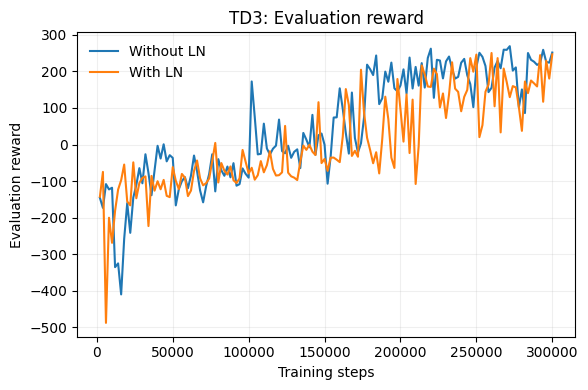

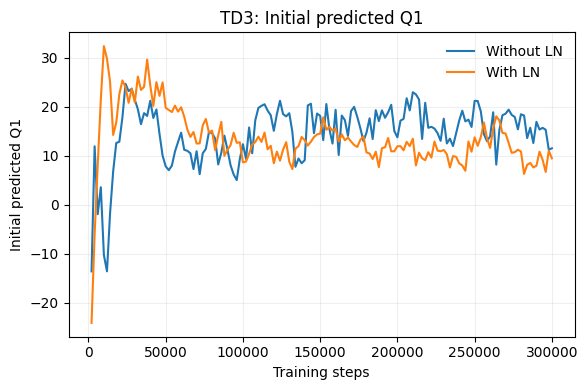

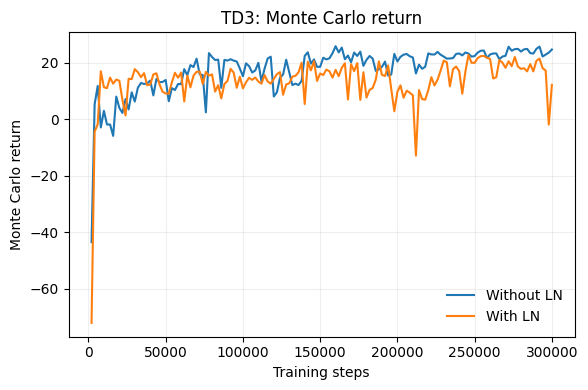

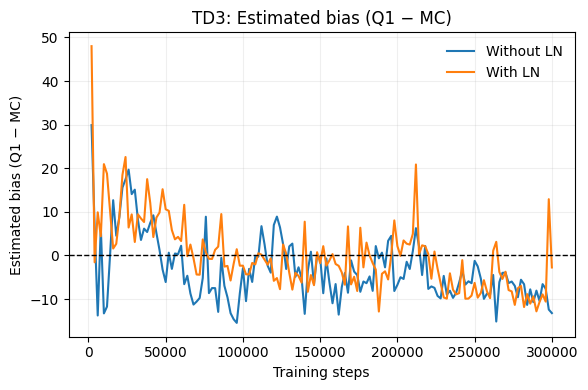

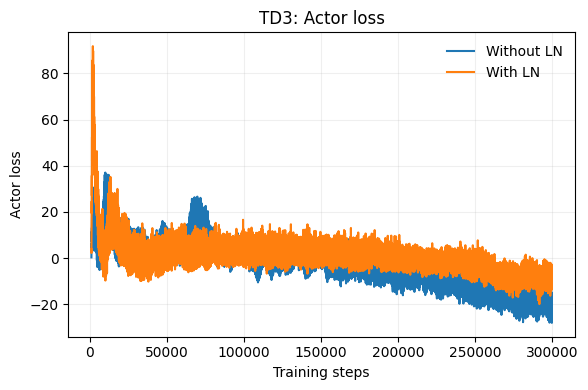

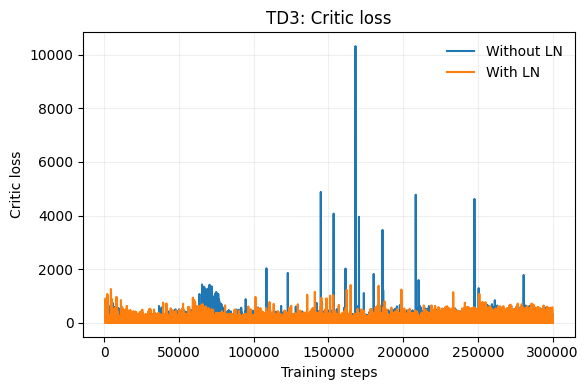

Images saved in: /content/plots_td3


In [15]:
output_dir = Path("plots_td3")
output_dir.mkdir(exist_ok=True)

metrics = [
    ("eval/reward", "Evaluation reward"),
    ("Q_vs_MC/Q_value", "Initial predicted Q1"),
    ("Q_vs_MC/Monte_Carlo", "Monte Carlo return"),
    ("Q_vs_MC/Bias", "Estimated bias (Q1 − MC)"),
    ("loss/actor", "Actor loss"),
    ("loss/critic", "Critic loss"),
]

for tag, title in metrics:
    fig, ax = plt.subplots(figsize=(6, 4))

    for condition, label, color in [
        ("noLN", "Without LN", "tab:blue"),
        ("LN", "With LN", "tab:orange"),
    ]:
        curves = [runs[condition][seed][tag] for seed in SEEDS]

        # Align curves within the range covered by all five seeds.
        start = max(min(curve) for curve in curves)
        end = min(max(curve) for curve in curves)

        steps = np.array(sorted(curves[0]))
        steps = steps[(steps >= start) & (steps <= end)]

        if len(steps) == 0:
            raise ValueError(f"No overlapping steps for {condition}: {tag}")

        values = []
        for curve in curves:
            x = sorted(curve)
            y = [curve[step] for step in x]
            values.append(np.interp(steps, x, y))

        values = np.array(values)
        mean = values.mean(axis=0)

        ax.plot(steps, mean, label=label, color=color)

    if tag == "Q_vs_MC/Bias":
        ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(f"TD3: {title}")
    ax.set_xlabel("Training steps")
    ax.set_ylabel(title)
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
    fig.tight_layout()

    filename = tag.replace("/", "_")
    fig.savefig(output_dir / f"{filename}.png", dpi=300)
    fig.savefig(output_dir / f"{filename}.pdf")

    plt.show()
    plt.close(fig)

print(f"Images saved in: {output_dir.resolve()}")

In [16]:
import pandas as pd
from pathlib import Path
from IPython.display import display

ALGORITHM = "TD3"  # Change to "DDPG" in your DDPG notebook

metrics = [
    ("eval/reward", "Evaluation reward"),
    ("Q_vs_MC/Q_value", "Predicted Q"),
    ("Q_vs_MC/Monte_Carlo", "Monte Carlo return"),
    ("Q_vs_MC/Bias", "Estimated bias"),
    ("loss/actor", "Actor loss"),
    ("loss/critic", "Critic loss"),
]

columns = {}

for condition, label in [
    ("noLN", "Without LN"),
    ("LN", "With LN"),
]:
    for seed, history in sorted(runs[condition].items()):
        column = {}

        for tag, name in metrics:
            values = history[tag]
            last_step = max(values)
            column[name] = values[last_step]

        columns[f"{label} — seed {seed}"] = column

table = pd.DataFrame(columns)
table.index.name = "Measure"

print(f"{ALGORITHM}: final logged values")
display(table.round(2))

# Save the full-precision numbers.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

csv_path = output_dir / f"{ALGORITHM.lower()}_final_values.csv"
table.to_csv(csv_path)

print(f"Numbers saved in: {csv_path}")

TD3: final logged values


,Without LN — seed 0,With LN — seed 0
Measure,,
Evaluation reward,251.76,246.96
Predicted Q,11.51,9.47
Monte Carlo return,24.74,12.24
Estimated bias,-13.23,-2.77
Actor loss,-19.86,-11.98
Critic loss,29.87,1.93


Numbers saved in: outputs/td3_final_values.csv


In [17]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

folders = [
    Path(name)
    for name in ("outputs", "plots", "plots_td3")
    if Path(name).is_dir()
]

if not folders:
    raise FileNotFoundError("No outputs or plots folders found.")

archive_name = "rl_results.zip"

with ZipFile(archive_name, "w", compression=ZIP_DEFLATED) as archive:
    for folder in folders:
        for file in folder.rglob("*"):
            if file.is_file():
                archive.write(file, arcname=str(file))

print("Included:", ", ".join(str(folder) for folder in folders))

# Download in Colab, or show a download link in Jupyter.
try:
    from google.colab import files
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(archive_name))
else:
    files.download(archive_name)

Included: outputs, plots_td3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>